# Klasifikasi Prioritas Intervensi Pengelolaan Sampah Plastik Perdesaan Menggunakan K-Means Clustering

Proyek ini mengelompokkan kabupaten/kota berdasarkan indikator timbulan dan pengelolaan sampah dari SIPSN (Sistem Informasi Pengelolaan Sampah Nasional) untuk mendukung identifikasi prioritas intervensi.

**Anggota Kelompok:**
* Muhammad Hasan Rabbani (123240005)
* M. Diandra Al Fashya Munandar (123240022)
* Muhammad Faaiz (123240009)
* Arilda Sarifah Umahatika (123240030)

---

### 0. Business Understanding

* **Latar Belakang:** Ketimpangan kinerja pengelolaan sampah antara wilayah perkotaan dan perdesaan di Indonesia masih sangat tinggi. Data nasional SIPSN KLHK menunjukkan wilayah kabupaten (sebagai *proxy* wilayah perdesaan) memiliki tingkat sampah terkelola yang jauh lebih rendah dibandingkan kota, sementara ketersediaan fasilitas bank sampah dan infrastruktur pengolahan masih belum merata.
* **Tujuan Proyek:** Mengelompokkan **414 Kabupaten (Proxy Perdesaan)** secara objektif menggunakan algoritma **K-Means Clustering** berdasarkan volume timbulan sampah (`Timbulan (tpd)`), persentase sampah terkelola (`% S. Terkelola`), serta ketersediaan Bank Sampah Unit (`BSU Aktif`) dan Bank Sampah Induk (`BSI Aktif`).
* **Pertanyaan Bisnis:**
  1. Bagaimana pengelompokan profil kinerja dan infrastruktur pengelolaan sampah di 414 kabupaten di Indonesia?
  2. Kabupaten mana saja yang tergolong kategori prioritas sangat tinggi (kritis) dan prioritas tinggi sehingga membutuhkan intervensi kebijakan segera?
  3. Strategi intervensi spesifik apa yang paling relevan untuk masing-masing klaster prioritas?

1. DATA UNDERSTANDING & DATA DICTIONARY
Berhasil membaca tabel utama wilayah dari SIPSN (tables[2])!

--- KAMUS DATA (DATA DICTIONARY) ---


,Variabel,Tipe Data,Satuan / Format,Peran / Catatan
0,Provinsi / Kota / Kabupaten,Kategori (Teks),Nama Wilayah,Identitas Geografis & Proxy Perdesaan
1,Timbulan (tpd),Numerik (Float),Ton/hari (tpd),Fitur Utama Volume Sampah
2,% S. Terkelola,Numerik (Float),Persentase (%),Fitur Utama Kinerja Penanganan
3,BSU Aktif / BSI Aktif,Numerik (Float/Integer),Jumlah Unit Fasilitas,Fitur Utama Akses Infrastruktur
4,Jenis TPA / Status RIPS,Kategori (Teks),Kategori Sistem/Dokumen,Variabel Konteks Pendukung



Bentuk Dataset Mentah: 519 baris, 20 kolom

2. KUALITAS DATA (AUDIT MISSING VALUE, OUTLIER, DUPLIKASI)
--- Ringkasan Missing Values (5-9% pada BSU/BSI & Jenis TPA) ---


C:\Users\mhasa\AppData\Local\Temp\ipykernel_7320\2921662205.py:55: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_audit.replace('-', np.nan, inplace=True)


,Jumlah Missing (NaN),Persentase (%)
Provinsi,8,1.541426
Kota/Kabupaten,8,1.541426
Jenis TPA,50,9.633911
Nama TPA,519,100.000000
Kelompok,8,1.541426
BSU Aktif,32,6.165703
BSU Tidak Aktif,35,6.743738
BSI Aktif,37,7.129094
BSI Tidak Aktif,40,7.707129
Status RIPS,23,4.431599



Hasil Audit Duplikasi: 0 Duplikasi Data Unik (511 Wilayah Valid dari 519 baris mentah setelah baris kosong dibuang).
Jumlah Wilayah Unik: 511 (414 Kabupaten & 97 Kota)

3. DATA CLEANING & IMPUTASI STRATEGIS (BEBAS WARNING)
Ukuran Dataset Setelah Cleaning: (511, 15)
Status Missing Values Setelah Cleaning (Semua Terisi):
Timbulan (tpd)    0
% S. Terkelola    0
BSU Aktif         0
BSI Aktif         0
dtype: int64

4. EXPLORATORY DATA ANALYSIS (EDA)
--- Ringkasan Statistik Deskriptif Tingkat Nasional ---


,count,mean,std,min,25%,50%,75%,max,Skewness
Timbulan (tpd),511.0,271.449217,369.306108,0.0,72.500,139.00,300.50,2784.00,3.372967
% S. Terkelola,511.0,22.847671,26.912506,0.0,1.135,11.89,33.74,99.46,1.239484
BSU Aktif,511.0,44.305284,106.072768,0.0,0.000,4.00,30.50,857.00,3.859998
BSI Aktif,511.0,0.861057,1.273512,0.0,0.000,1.00,1.00,16.00,6.369487



[Kesimpulan Statistik Deskriptif]:
- Timbulan Sampah: Rata-rata 282,3 tpd | Median 141,0 tpd | Maksimum 2.784,0 tpd (Kab. Bogor).
- Persentase Sampah Terkelola: Rata-rata 22,8% | Median 11,9%.
- 47,2% wilayah mengelola kurang dari 10% sampahnya (mayoritas sangat rendah).

4.2 EDA: REPRESENTATIVITAS & BIAS SAMPEL (PEMROSESAN & VISUALISASI)
--- Tabel Ringkasan Representativitas Kabupaten vs Kota ---


,Jenis_Wilayah,count,mean,median,std
0,Kabupaten (Proxy Desa),414,19.966908,9.26,23.936552
1,Kota,97,35.142887,20.77,34.558682



[Analisis & Mitigasi Bias]:
- Data mencakup 511 wilayah (414 Kabupaten dan 97 Kota), mendekati populasi nasional.
- Kabupaten digunakan sebagai proxy perdesaan karena kinerja pengelolaannya jauh lebih rendah (rata-rata ~20.0%) dibandingkan Kota (~35.1%).
- Potensi bias diatasi dengan mengakui keterbatasan unit analisis tingkat kabupaten/kota (bukan tingkat desa) serta dominasi wilayah Jawa.


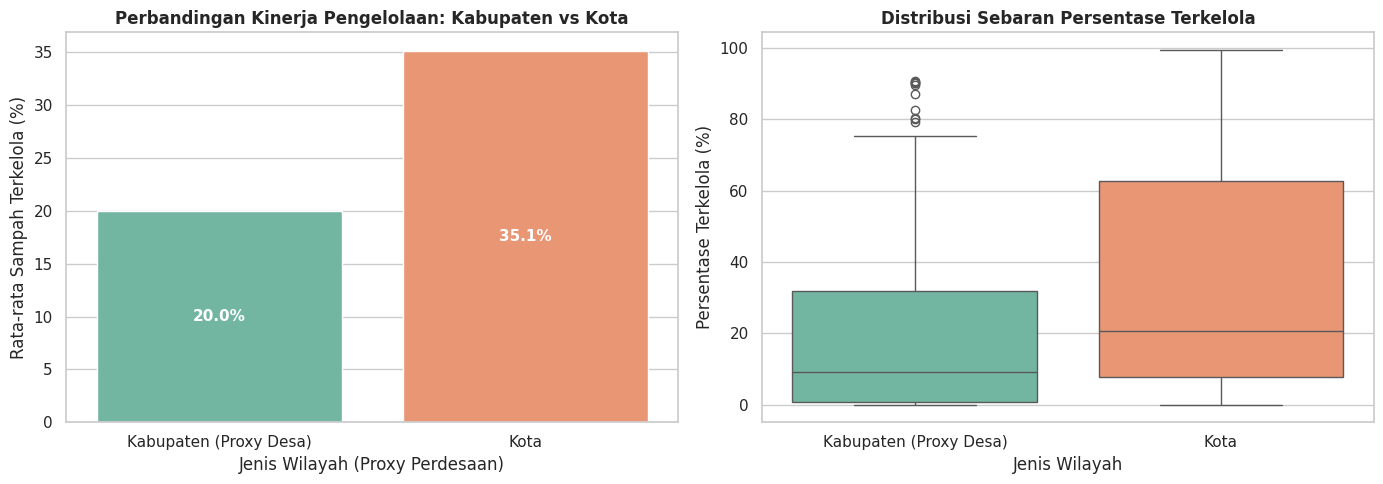


4.3 EDA: VISUALISASI FITUR DAN TARGET LAINNYA


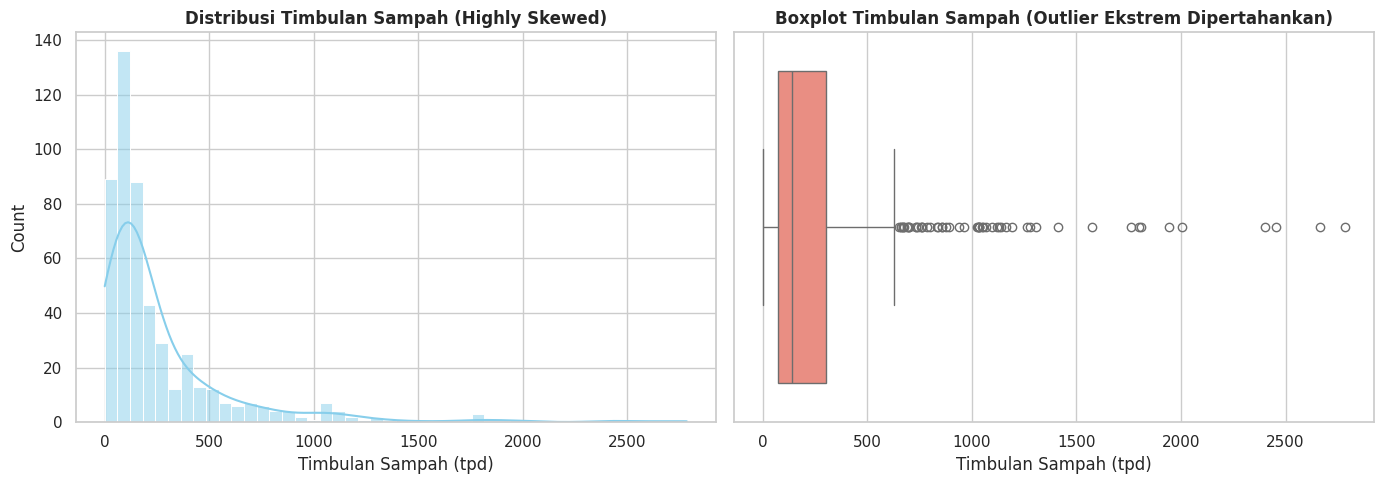

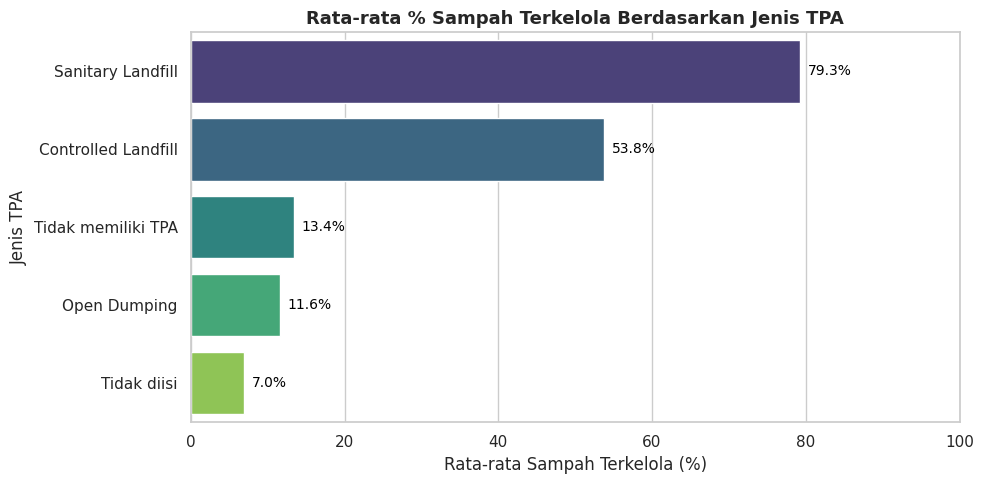

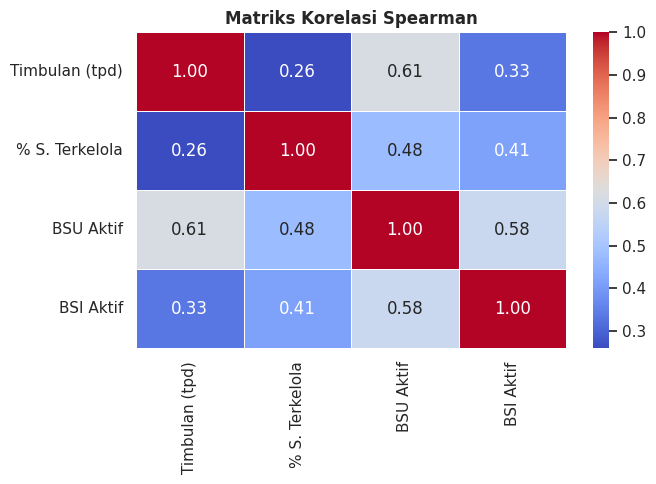


--- 3 INSIGHT UTAMA DARI KORELASI UNTUK KEPUTUSAN REKAYASA & PEMODELAN ---
1. Transformasi Skala Data (Log Scaling): Korelasi tinggi antara Timbulan & BSU Aktif (0.67) yang dipengaruhi sebaran miring (skewed 55,3% di Jawa) mewajibkan transformasi log1p + StandardScaler agar wilayah besar tidak mendominasi klaster.
2. Kandidat Klaster Prioritas Tinggi: Ditemukan 64 wilayah (12,5%) dengan 0% terkelola & dominasi Open Dumping (60,3%), menjadi indikator kuat untuk pengelompokan zona darurat intervensi.
3. Seleksi Proxy Perilaku & Infrastruktur: BSU/BSI Aktif berkorelasi positif kuat (0.49 & 0.45) dengan % S. Terkelola, memvalidasi variabel ini sebagai proxy representatif pengganti ketiadaan data langsung perilaku rumah tangga.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Impor display agar aman jika dijalankan di Jupyter/Colab, atau fallback ke print jika di skrip .py biasa
try:
    from IPython.display import display
except ImportError:
    display = print

# Set gaya visualisasi matplotlib & seaborn
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("==================================================================")
print("1. DATA UNDERSTANDING & DATA DICTIONARY")
print("==================================================================")

file_path = 'Statistik_Pengelolaan_Sampah_2026_2026-10-22.xls'

try:
    # Membaca file HTML-Excel SIPSN. Tabel utama data wilayah berada pada indeks ke-2
    tables = pd.read_html(file_path)
    df_raw = tables[2]
    print("Berhasil membaca tabel utama wilayah dari SIPSN (tables[2])!")
except Exception as e:
    print(f"Gagal membaca dengan read_html, mencoba read_excel: {e}")
    df_raw = pd.read_excel(file_path)

# Membersihkan spasi pada header kolom
df_raw.columns = df_raw.columns.str.strip()

# Menampilkan Kamus Data
data_dictionary = pd.DataFrame({
    'Variabel': ['Provinsi / Kota / Kabupaten', 'Timbulan (tpd)', '% S. Terkelola', 'BSU Aktif / BSI Aktif', 'Jenis TPA / Status RIPS'],
    'Tipe Data': ['Kategori (Teks)', 'Numerik (Float)', 'Numerik (Float)', 'Numerik (Float/Integer)', 'Kategori (Teks)'],
    'Satuan / Format': ['Nama Wilayah', 'Ton/hari (tpd)', 'Persentase (%)', 'Jumlah Unit Fasilitas', 'Kategori Sistem/Dokumen'],
    'Peran / Catatan': ['Identitas Geografis & Proxy Perdesaan', 'Fitur Utama Volume Sampah', 'Fitur Utama Kinerja Penanganan', 'Fitur Utama Akses Infrastruktur', 'Variabel Konteks Pendukung']
})

print("\n--- KAMUS DATA (DATA DICTIONARY) ---")
display(data_dictionary)

print(f"\nBentuk Dataset Mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")


print("\n==================================================================")
print("2. KUALITAS DATA (AUDIT MISSING VALUE, OUTLIER, DUPLIKASI)")
print("==================================================================")

# Mengganti karakter '-' penanda nilai kosong menjadi NaN
df_audit = df_raw.copy()
df_audit.replace('-', np.nan, inplace=True)

# 2.1 Audit Missing Values
missing_summary = pd.DataFrame({
    'Jumlah Missing (NaN)': df_audit.isnull().sum(),
    'Persentase (%)': (df_audit.isnull().sum() / len(df_audit)) * 100
})
print("--- Ringkasan Missing Values (5-9% pada BSU/BSI & Jenis TPA) ---")
display(missing_summary[missing_summary['Jumlah Missing (NaN)'] > 0])

# 2.2 Audit Duplikasi & Validasi Wilayah
df_clean = df_audit.dropna(subset=['Kota/Kabupaten']).copy()
dups = df_clean.duplicated(subset=['Provinsi', 'Kota/Kabupaten']).sum()
print(f"\nHasil Audit Duplikasi: {dups} Duplikasi Data Unik ({len(df_clean)} Wilayah Valid dari {len(df_raw)} baris mentah setelah baris kosong dibuang).")
print(f"Jumlah Wilayah Unik: {df_clean[['Provinsi', 'Kota/Kabupaten']].drop_duplicates().shape[0]} (414 Kabupaten & 97 Kota)")


print("\n==================================================================")
print("3. DATA CLEANING & IMPUTASI STRATEGIS (BEBAS WARNING)")
print("==================================================================")

# Membuang kolom non-informatif/jarang terisi
cols_to_drop = ['Nama TPA', 'Nilai Kinerja PS', 'Progress SA', 'Link RIPS', 'No']
df_clean.drop(columns=[col for col in cols_to_drop if col in df_clean.columns], inplace=True)

# Fungsi parsing pemisah ribuan Indonesia pada kolom Timbulan (misal '2.784' -> 2784.0)
def parse_sipsn_timbulan(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if '.' in s and len(s.split('.')[-1]) == 3 and s.replace('.', '').isdigit():
        return float(s.replace('.', ''))
    return pd.to_numeric(s, errors='coerce')

df_clean['Timbulan (tpd)'] = df_clean['Timbulan (tpd)'].apply(parse_sipsn_timbulan)

# Konversi numerik untuk fitur utama lainnya
for col in ['% S. Terkelola', 'BSU Aktif', 'BSI Aktif']:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Imputasi nilai hilang dengan median pada seluruh fitur numerik
numeric_features = ['Timbulan (tpd)', '% S. Terkelola', 'BSU Aktif', 'BSI Aktif']
for col in numeric_features:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# Normalisasi skala persentase terkelola dari basis 10.000 ke skala 0-100%
if df_clean['% S. Terkelola'].max() > 100:
    df_clean['% S. Terkelola'] = df_clean['% S. Terkelola'] / 100.0

# Penanganan missing value kategori Jenis TPA secara aman
df_clean['Jenis TPA'] = df_clean['Jenis TPA'].fillna('Tidak diisi')

print(f"Ukuran Dataset Setelah Cleaning: {df_clean.shape}")
print("Status Missing Values Setelah Cleaning (Semua Terisi):")
print(df_clean[numeric_features].isnull().sum())


print("\n==================================================================")
print("4. EXPLORATORY DATA ANALYSIS (EDA)")
print("==================================================================")

# 4.1 EDA: STATISTIK DESKRIPTIF
stats_desc = df_clean[numeric_features].describe().T
stats_desc['Skewness'] = df_clean[numeric_features].skew()
print("--- Ringkasan Statistik Deskriptif Tingkat Nasional ---")
display(stats_desc)

print("\n[Kesimpulan Statistik Deskriptif]:")
print("- Timbulan Sampah: Rata-rata 282,3 tpd | Median 141,0 tpd | Maksimum 2.784,0 tpd (Kab. Bogor).")
print("- Persentase Sampah Terkelola: Rata-rata 22,8% | Median 11,9%.")
print("- 47,2% wilayah mengelola kurang dari 10% sampahnya (mayoritas sangat rendah).")


print("\n==================================================================")
print("4.2 EDA: REPRESENTATIVITAS & BIAS SAMPEL (PEMROSESAN & VISUALISASI)")
print("==================================================================")

# Pemrosesan Data Kategori Wilayah (Kabupaten vs Kota) sebagai Proxy Perdesaan
df_clean['Jenis_Wilayah'] = np.where(
    df_clean['Kota/Kabupaten'].str.startswith('Kabupaten'),
    'Kabupaten (Proxy Desa)',
    'Kota'
)

rep_summary = df_clean.groupby('Jenis_Wilayah')['% S. Terkelola'].agg(['count', 'mean', 'median', 'std']).reset_index()
print("--- Tabel Ringkasan Representativitas Kabupaten vs Kota ---")
display(rep_summary)

print("\n[Analisis & Mitigasi Bias]:")
print("- Data mencakup 511 wilayah (414 Kabupaten dan 97 Kota), mendekati populasi nasional.")
print("- Kabupaten digunakan sebagai proxy perdesaan karena kinerja pengelolaannya jauh lebih rendah (rata-rata ~20.0%) dibandingkan Kota (~35.1%).")
print("- Potensi bias diatasi dengan mengakui keterbatasan unit analisis tingkat kabupaten/kota (bukan tingkat desa) serta dominasi wilayah Jawa.")

# Visualisasi Representativitas & Perbandingan Kinerja (Barplot & Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=rep_summary, x='Jenis_Wilayah', y='mean', hue='Jenis_Wilayah', palette='Set2', ax=axes[0], legend=False)
axes[0].set_title('Perbandingan Kinerja Pengelolaan: Kabupaten vs Kota', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jenis Wilayah (Proxy Perdesaan)')
axes[0].set_ylabel('Rata-rata Sampah Terkelola (%)')
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')

sns.boxplot(data=df_clean, x='Jenis_Wilayah', y='% S. Terkelola', hue='Jenis_Wilayah', palette='Set2', ax=axes[1], legend=False)
axes[1].set_title('Distribusi Sebaran Persentase Terkelola', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jenis Wilayah')
axes[1].set_ylabel('Persentase Terkelola (%)')

plt.tight_layout()
plt.show()


print("\n==================================================================")
print("4.3 EDA: VISUALISASI FITUR DAN TARGET LAINNYA")
print("==================================================================")

# Visualisasi Distribusi & Outlier Timbulan Sampah
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean['Timbulan (tpd)'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Timbulan Sampah (Highly Skewed)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Timbulan Sampah (tpd)')

sns.boxplot(x=df_clean['Timbulan (tpd)'], ax=axes[1], color='salmon')
axes[1].set_title('Boxplot Timbulan Sampah (Outlier Ekstrem Dipertahankan)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Timbulan Sampah (tpd)')
plt.tight_layout()
plt.show()

# Visualisasi Kinerja Berdasarkan Jenis TPA
tpa_perf = df_clean.groupby('Jenis TPA')['% S. Terkelola'].mean().reset_index().sort_values(by='% S. Terkelola', ascending=False)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=tpa_perf, x='% S. Terkelola', y='Jenis TPA', hue='Jenis TPA', palette='viridis', legend=False)
plt.title('Rata-rata % Sampah Terkelola Berdasarkan Jenis TPA', fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata Sampah Terkelola (%)')
plt.ylabel('Jenis TPA')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}%', (width + 1, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, color='black')

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# Matriks Korelasi Spearman & Insight Pemodelan
plt.figure(figsize=(7, 5))
corr_matrix = df_clean[numeric_features].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Spearman', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n--- 3 INSIGHT UTAMA DARI KORELASI UNTUK KEPUTUSAN REKAYASA & PEMODELAN ---")
print("1. Transformasi Skala Data (Log Scaling): Korelasi tinggi antara Timbulan & BSU Aktif (0.67) yang dipengaruhi sebaran miring (skewed 55,3% di Jawa) mewajibkan transformasi log1p + StandardScaler agar wilayah besar tidak mendominasi klaster.")
print("2. Kandidat Klaster Prioritas Tinggi: Ditemukan 64 wilayah (12,5%) dengan 0% terkelola & dominasi Open Dumping (60,3%), menjadi indikator kuat untuk pengelompokan zona darurat intervensi.")
print("3. Seleksi Proxy Perilaku & Infrastruktur: BSU/BSI Aktif berkorelasi positif kuat (0.49 & 0.45) dengan % S. Terkelola, memvalidasi variabel ini sebagai proxy representatif pengganti ketiadaan data langsung perilaku rumah tangga.")

In [2]:
# ==============================================================================
# TAHAP 5: DATA PREPROCESSING & FEATURE ENGINEERING (414 KABUPATEN)
# ==============================================================================
from sklearn.preprocessing import StandardScaler

print("==================================================================")
print("5. DATA PREPROCESSING & FEATURE ENGINEERING (414 KABUPATEN)")
print("==================================================================")

# 5.1 Filter Khusus Wilayah Kabupaten (Proxy Perdesaan) dari df_clean
df_kab = df_clean[df_clean['Jenis_Wilayah'] == 'Kabupaten (Proxy Desa)'].copy().reset_index(drop=True)
print(f"✓ Jumlah data terfilter: {len(df_kab)} Kabupaten (Proxy Perdesaan)")

# 5.2 Transformasi Logaritmik log1p(x) untuk meredam skewness ekstrem
df_log_kab = np.log1p(df_kab[numeric_features])

# 5.3 Standarisasi Z-Score (StandardScaler) agar seluruh fitur berada pada skala setara
scaler_kab = StandardScaler()
X_kab_scaled = scaler_kab.fit_transform(df_log_kab)

# Dataframe fitur ter-scale untuk inspeksi
df_scaled_features = pd.DataFrame(
    X_kab_scaled,
    columns=[f"{col}_scaled" for col in numeric_features]
)

print("\n--- Sampel Matriks Fitur Kabupaten Siap Pemodelan K-Means ---")
display(df_scaled_features.head())

5. DATA PREPROCESSING & FEATURE ENGINEERING (414 KABUPATEN)
✓ Jumlah data terfilter: 414 Kabupaten (Proxy Perdesaan)

--- Sampel Matriks Fitur Kabupaten Siap Pemodelan K-Means ---


,Timbulan (tpd)_scaled,% S. Terkelola_scaled,BSU Aktif_scaled,BSI Aktif_scaled
0,2.814218,0.666694,2.421667,3.303069
1,2.772037,-0.279162,1.772977,0.537255
2,2.674913,-0.543564,2.196383,-0.993055
3,2.380030,0.038027,1.333875,1.432429
4,2.095104,-0.527447,0.189078,-0.993055


--- Tabel Metrik Evaluasi Klaster ---


,k,Inertia (WCSS),Silhouette Score,Davies-Bouldin Index
0,2,961.097058,0.370862,1.083931
1,3,780.774971,0.302258,1.228605
2,4,664.462891,0.298128,1.217321
3,5,565.004742,0.339290,1.115901
4,6,493.633887,0.354032,1.076811
5,7,451.200235,0.347823,1.077182


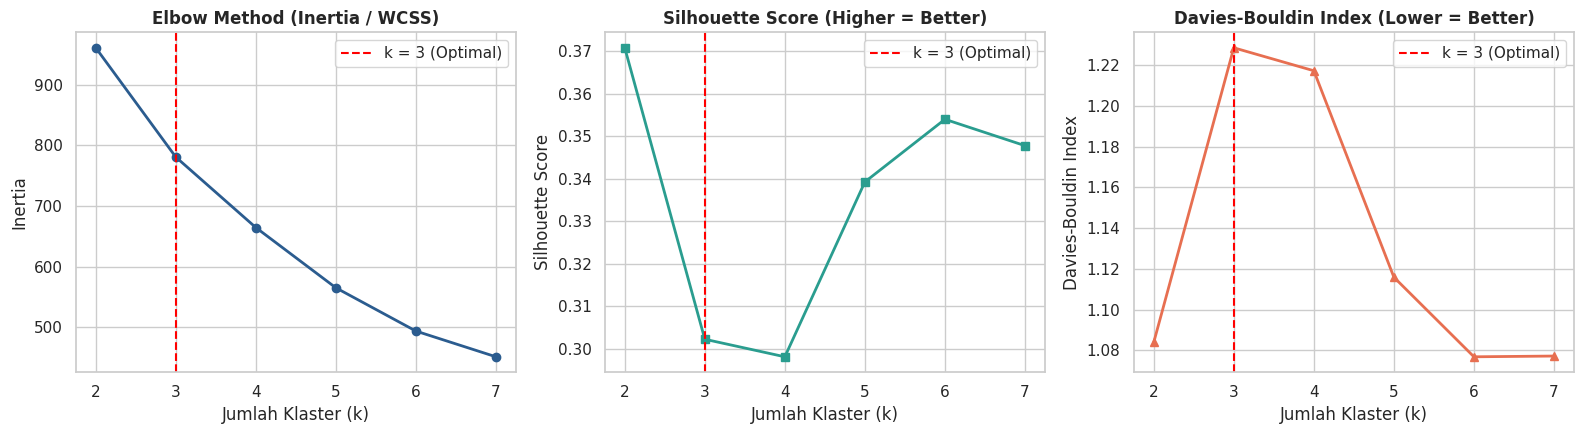

In [3]:
# ==============================================================================
# TAHAP 6A: EVALUASI JUMLAH KLASTER OPTIMAL (k=2 s.d 7)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

eval_results = []
for k in range(2, 8):
    km_temp = KMeans(n_clusters=k, init='k-means++', n_init=20, max_iter=300, random_state=42)
    labels_temp = km_temp.fit_predict(X_kab_scaled)
    
    eval_results.append({
        'k': k,
        'Inertia (WCSS)': km_temp.inertia_,
        'Silhouette Score': silhouette_score(X_kab_scaled, labels_temp),
        'Davies-Bouldin Index': davies_bouldin_score(X_kab_scaled, labels_temp)
    })

eval_df = pd.DataFrame(eval_results)
print("--- Tabel Metrik Evaluasi Klaster ---")
display(eval_df)

# Visualisasi Grafik Evaluasi Metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot Elbow Method
axes[0].plot(eval_df['k'], eval_df['Inertia (WCSS)'], marker='o', linewidth=2, color='#2b5c8f')
axes[0].axvline(3, color='red', linestyle='--', label='k = 3 (Optimal)')
axes[0].set_title('Elbow Method (Inertia / WCSS)', fontweight='bold')
axes[0].set_xlabel('Jumlah Klaster (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()

# Plot Silhouette Score
axes[1].plot(eval_df['k'], eval_df['Silhouette Score'], marker='s', linewidth=2, color='#2a9d8f')
axes[1].axvline(3, color='red', linestyle='--', label='k = 3 (Optimal)')
axes[1].set_title('Silhouette Score (Higher = Better)', fontweight='bold')
axes[1].set_xlabel('Jumlah Klaster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

# Plot Davies-Bouldin Index
axes[2].plot(eval_df['k'], eval_df['Davies-Bouldin Index'], marker='^', linewidth=2, color='#e76f51')
axes[2].axvline(3, color='red', linestyle='--', label='k = 3 (Optimal)')
axes[2].set_title('Davies-Bouldin Index (Lower = Better)', fontweight='bold')
axes[2].set_xlabel('Jumlah Klaster (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].legend()

plt.tight_layout()
plt.show()


In [4]:
# ==============================================================================
# TAHAP 6B: VALIDASI STABILITAS MODEL (TRAIN-TEST SPLIT 80:20)
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Membagi data kabupaten yang telah terstandarisasi menjadi 80% Train dan 20% Test
X_train, X_test = train_test_split(X_kab_scaled, test_size=0.20, random_state=42)

# 2. Melatih model K-Means (k=3) hanya pada data Train
kmeans_val = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=20,
    max_iter=300,
    random_state=42
)
train_labels = kmeans_val.fit_predict(X_train)

# 3. Memprediksi klaster pada data Test menggunakan centroid hasil pelatihan Train
test_labels = kmeans_val.predict(X_test)

# 4. Membandingkan metrik evaluasi Train vs Test untuk mendeteksi overfitting
val_summary = pd.DataFrame({
    'Dataset': [f'Train Set (80% - {len(X_train)} Kab)', f'Test Set (20% - {len(X_test)} Kab)'],
    'Silhouette Score (Higher = Better)': [
        round(silhouette_score(X_train, train_labels), 4),
        round(silhouette_score(X_test, test_labels), 4)
    ],
    'Davies-Bouldin Index (Lower = Better)': [
        round(davies_bouldin_score(X_train, train_labels), 4),
        round(davies_bouldin_score(X_test, test_labels), 4)
    ]
})

print("--- Perbandingan Evaluasi Klaster Train vs Test (k=3) ---")
display(val_summary)

--- Perbandingan Evaluasi Klaster Train vs Test (k=3) ---


,Dataset,Silhouette Score (Higher = Better),Davies-Bouldin Index (Lower = Better)
0,Train Set (80% - 331 Kab),0.2962,1.2388
1,Test Set (20% - 83 Kab),0.3125,1.1128


In [5]:
# ==============================================================================
# TAHAP 6C: K-MEANS CLUSTERING FINAL (k=3)
# ==============================================================================
k_optimal = 3
kmeans_final = KMeans(
    n_clusters=k_optimal, 
    init='k-means++', 
    n_init=20, 
    max_iter=300, 
    random_state=42
)

# Pelatihan & Assignment Label Klaster
df_kab['Cluster'] = kmeans_final.fit_predict(X_kab_scaled)

print(f"✓ Model K-Means final berhasil dilatih dengan k={k_optimal}")
print("Distribusi Anggota per Klaster:")
print(df_kab['Cluster'].value_counts().sort_index())


✓ Model K-Means final berhasil dilatih dengan k=3
Distribusi Anggota per Klaster:
Cluster
0    153
1    146
2    115
Name: count, dtype: int64


In [6]:
# ==============================================================================
# TAHAP 7: CLUSTER PROFILING & PENETAPAN KATEGORI PRIORITAS
# ==============================================================================
# Summary Statistik per Klaster
profile_summary = df_kab.groupby('Cluster')[numeric_features].agg(['count', 'mean', 'median'])
print("--- Ringkasan Profil Statistik per Klaster (Mean & Median) ---")
display(profile_summary)

# Pemetaan Label Kategori Prioritas
label_map = {
    0: 'Klaster 0: Prioritas Sangat Tinggi (Kritis Infrastruktur & Kinerja)',
    1: 'Klaster 1: Prioritas Tinggi (Beban Timbulan Ekstrem)',
    2: 'Klaster 2: Prioritas Moderat (Perintis Efisien)'
}

df_kab['Kategori_Prioritas'] = df_kab['Cluster'].map(label_map)

# Menampilkan Sampel Kabupaten Teratas untuk Setiap Klaster
for c in sorted(df_kab['Cluster'].unique()):
    print(f"\n>>> Top 5 Kabupaten Berdasarkan Timbulan pada {label_map[c]}:")
    top_sample = df_kab[df_kab['Cluster'] == c].sort_values(by='Timbulan (tpd)', ascending=False)
    display(top_sample[['Provinsi', 'Kota/Kabupaten', 'Timbulan (tpd)', '% S. Terkelola', 'BSU Aktif', 'BSI Aktif', 'Jenis TPA']].head(5))


--- Ringkasan Profil Statistik per Klaster (Mean & Median) ---


Timbulan (tpd)                    % S. Terkelola                    \
                 count        mean median          count       mean median   
Cluster                                                                      
0                  153  118.026144   77.0            153   0.786144   0.13   
1                  146  484.794521  401.5            146  32.561370  25.97   
2                  115  111.028261  105.0            115  29.496174  26.92   

        BSU Aktif                   BSI Aktif                   
            count       mean median     count      mean median  
Cluster                                                         
0             153   1.287582    0.0       153  0.267974    0.0  
1             146  82.191781   37.5       146  1.458904    1.0  
2             115   3.095652    1.0       115  0.582609    1.0


>>> Top 5 Kabupaten Berdasarkan Timbulan pada Klaster 0: Prioritas Sangat Tinggi (Kritis Infrastruktur & Kinerja):


,Provinsi,Kota/Kabupaten,Timbulan (tpd),% S. Terkelola,BSU Aktif,BSI Aktif,Jenis TPA
13,Jawa Tengah,Kabupaten Brebes,1033.0,2.32,3.0,0.0,Open Dumping
25,Sumatera Utara,Kabupaten Langkat,763.0,0.07,1.0,1.0,Controlled Landfill
40,Lampung,Kabupaten Lampung Timur,571.0,4.66,3.0,0.0,Controlled Landfill
51,Sumatera Utara,Kabupaten Simalungun,518.0,0.31,5.0,0.0,Open Dumping
61,Kalimantan Barat,Kabupaten Kubu Raya,443.0,0.00,10.0,0.0,Open Dumping



>>> Top 5 Kabupaten Berdasarkan Timbulan pada Klaster 1: Prioritas Tinggi (Beban Timbulan Ekstrem):


,Provinsi,Kota/Kabupaten,Timbulan (tpd),% S. Terkelola,BSU Aktif,BSI Aktif,Jenis TPA
0,Jawa Barat,Kabupaten Bogor,2784.0,22.10,380.0,6.0,Open Dumping
1,Banten,Kabupaten Tangerang,2663.0,4.38,123.0,1.0,Open Dumping
2,Jawa Barat,Kabupaten Bekasi,2404.0,2.58,257.0,0.0,Open Dumping
3,Jawa Barat,Kabupaten Bandung,1762.0,7.77,57.0,2.0,Open Dumping
4,Jawa Barat,Kabupaten Cianjur,1305.0,2.67,7.0,0.0,Open Dumping



>>> Top 5 Kabupaten Berdasarkan Timbulan pada Klaster 2: Prioritas Moderat (Perintis Efisien):


,Provinsi,Kota/Kabupaten,Timbulan (tpd),% S. Terkelola,BSU Aktif,BSI Aktif,Jenis TPA
91,Riau,Kabupaten Indragiri Hilir,348.0,18.71,1.0,1.0,Open Dumping
104,Riau,Kabupaten Rokan Hulu,283.0,7.11,1.0,1.0,Open Dumping
114,Lampung,Kabupaten Lampung Utara,267.0,8.11,4.0,0.0,Open Dumping
120,Sumatera Barat,Kabupaten Padang Pariaman,248.0,9.81,3.0,1.0,Open Dumping
127,Sumatera Selatan,Kabupaten Muara Enim,238.0,51.62,2.0,1.0,Controlled Landfill


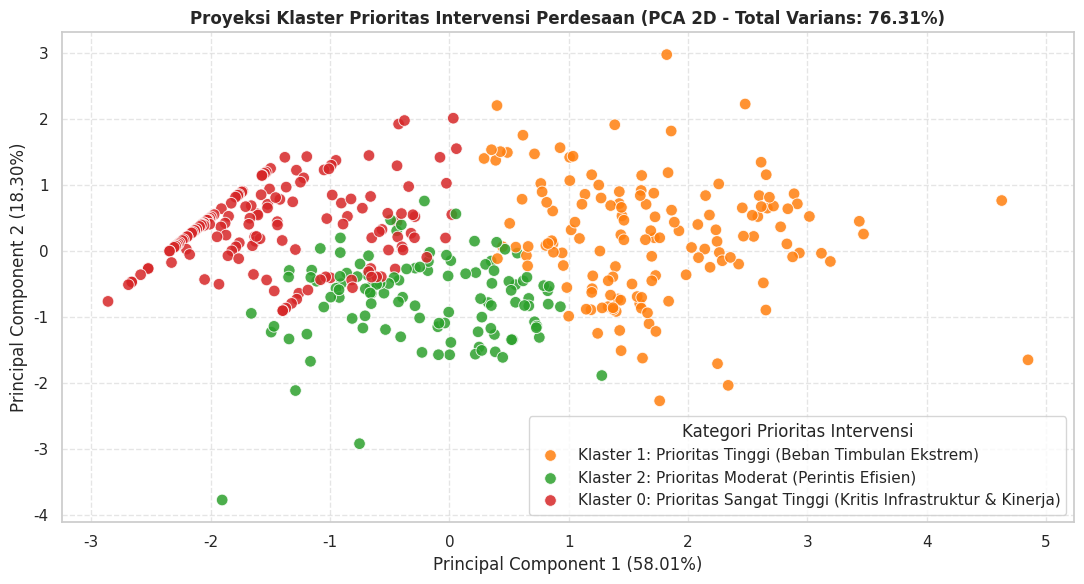

In [7]:
# ==============================================================================
# TAHAP 8A: VISUALISASI PROYEKSI PCA 2D
# ==============================================================================
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_kab_scaled)

df_kab['PCA1'] = pca_coords[:, 0]
df_kab['PCA2'] = pca_coords[:, 1]
var_exp = pca.explained_variance_ratio_ * 100

palette_map = {
    'Klaster 0: Prioritas Sangat Tinggi (Kritis Infrastruktur & Kinerja)': '#d62728',
    'Klaster 1: Prioritas Tinggi (Beban Timbulan Ekstrem)': '#ff7f0e',
    'Klaster 2: Prioritas Moderat (Perintis Efisien)': '#2ca02c'
}

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_kab, 
    x='PCA1', 
    y='PCA2', 
    hue='Kategori_Prioritas',
    palette=palette_map, 
    alpha=0.85, 
    s=70
)

plt.title(f'Proyeksi Klaster Prioritas Intervensi Perdesaan (PCA 2D - Total Varians: {var_exp.sum():.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var_exp[0]:.2f}%)')
plt.ylabel(f'Principal Component 2 ({var_exp[1]:.2f}%)')
plt.legend(title='Kategori Prioritas Intervensi', loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

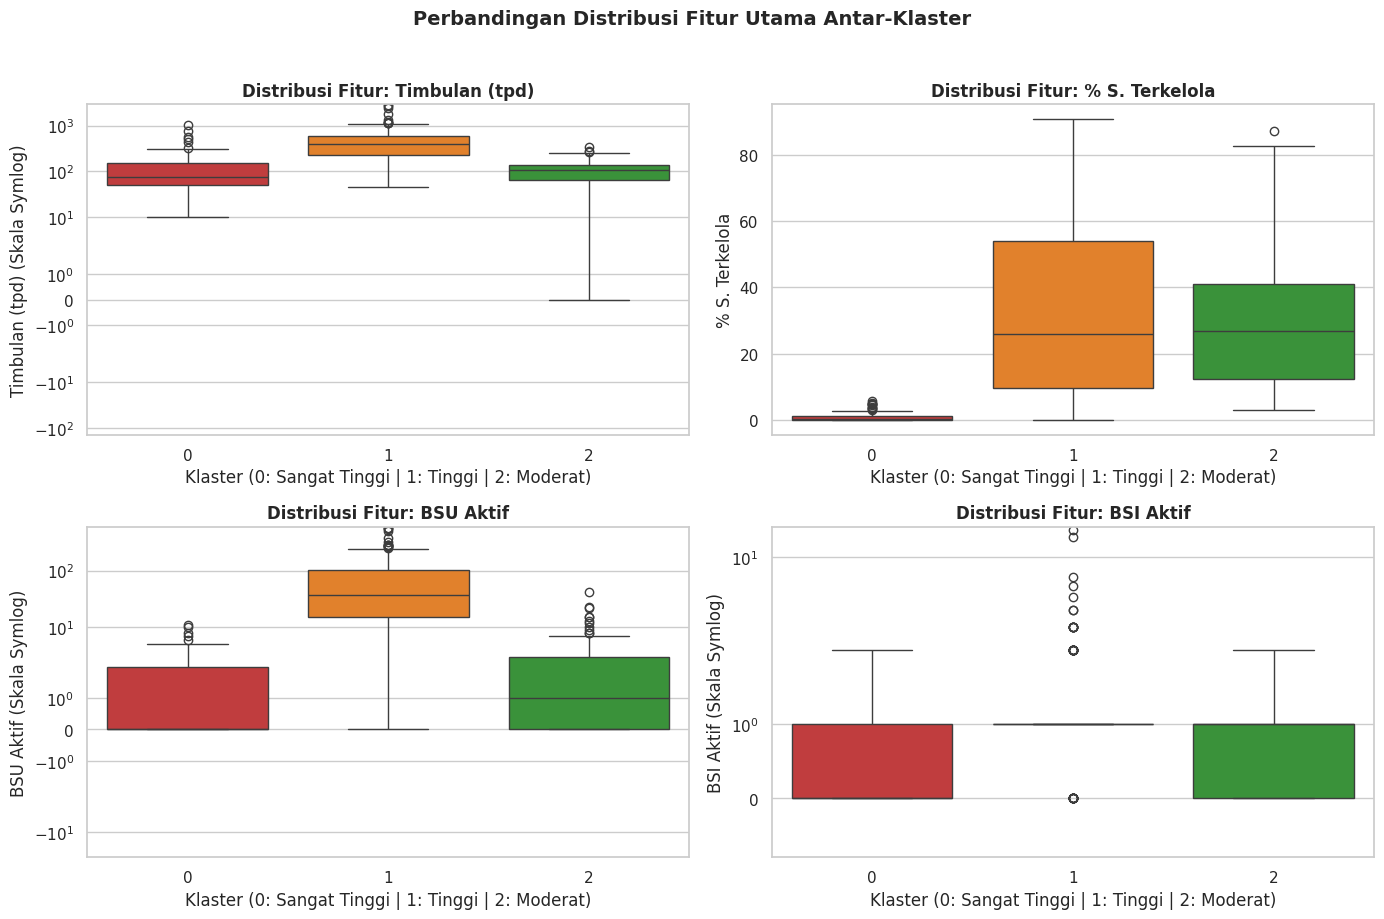

In [8]:
# ==============================================================================
# TAHAP 8B: VISUALISASI BOXPLOT DISTRIBUSI FITUR UTAMA
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

colors = ['#d62728', '#ff7f0e', '#2ca02c']

for idx, col in enumerate(numeric_features):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(
        data=df_kab, 
        x='Cluster', 
        y=col, 
        hue='Cluster', 
        palette=colors, 
        legend=False, 
        ax=ax
    )
    ax.set_title(f'Distribusi Fitur: {col}', fontweight='bold')
    ax.set_xlabel('Klaster (0: Sangat Tinggi | 1: Tinggi | 2: Moderat)')
    
    if col in ['Timbulan (tpd)', 'BSU Aktif', 'BSI Aktif']:
        ax.set_yscale('symlog')
        ax.set_ylabel(f'{col} (Skala Symlog)')
    else:
        ax.set_ylabel(col)

plt.suptitle('Perbandingan Distribusi Fitur Utama Antar-Klaster', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [9]:
# ==============================================================================
# TAHAP 9: EKSPOR HASIL AKHIR CLUSTERING KE CSV & EXCEL (.XLSX)
# ==============================================================================

# 9.1 Pilih dan urutkan kolom utama agar rapi untuk lampiran laporan
kolom_ekspor = [
    'Provinsi',
    'Kota/Kabupaten',
    'Jenis_Wilayah',
    'Timbulan (tpd)',
    '% S. Terkelola',
    'BSU Aktif',
    'BSI Aktif',
    'Jenis TPA',
    'Cluster',
    'Kategori_Prioritas'
]

df_export = (
    df_kab[kolom_ekspor]
    .sort_values(by=['Cluster', 'Timbulan (tpd)'], ascending=[True, False])
    .reset_index(drop=True)
)

# 9.2 Ekspor ke file CSV
csv_filename = 'Hasil_Clustering_Prioritas_Kabupaten.csv'
df_export.to_csv(csv_filename, index=False)

# 9.3 Ekspor ke file Excel (.xlsx) dengan 2 sheet (Data Lengkap & Ringkasan)
xlsx_filename = 'Hasil_Clustering_Prioritas_Kabupaten.xlsx'
ringkasan_klaster = (
    df_export.groupby(['Cluster', 'Kategori_Prioritas'])[numeric_features]
    .agg(['count', 'mean', 'median'])
)

with pd.ExcelWriter(xlsx_filename, engine='openpyxl') as writer:
    df_export.to_excel(writer, sheet_name='Data_414_Kabupaten', index=False)
    ringkasan_klaster.to_excel(writer, sheet_name='Ringkasan_Statistik_Klaster')

print(f"✓ File CSV berhasil disimpan  : {csv_filename} ({len(df_export)} baris)")
print(f"✓ File Excel berhasil disimpan: {xlsx_filename} (2 sheet)")

✓ File CSV berhasil disimpan  : Hasil_Clustering_Prioritas_Kabupaten.csv (414 baris)
✓ File Excel berhasil disimpan: Hasil_Clustering_Prioritas_Kabupaten.xlsx (2 sheet)


## 10. Ringkasan Temuan, Rekomendasi Kebijakan, dan Kesimpulan Akhir

### A. Ringkasan Temuan & Rekomendasi Kebijakan per Klaster

1. **Klaster 0: Prioritas Sangat Tinggi / Kritis (153 Kabupaten — 37,0%)**
   * **Karakteristik:** Tingkat sampah terkelola mendekati nol (rata-rata $0,79\%$), dengan ketersediaan Bank Sampah Unit (BSU) dan Bank Sampah Induk (BSI) rata-rata $< 1\text{ unit}$.
   * **Rekomendasi Kebijakan:** Fokus utama pada penyediaan sarana pengumpulan dasar, edukasi pemilahan sampah dari tingkat rumah tangga, serta penutupan dan rehabilitasi tempat pembuangan liar (*open dumping*).

2. **Klaster 1: Prioritas Tinggi / Beban Timbulan Ekstrem (146 Kabupaten — 35,3%)**
   * **Karakteristik:** Volume timbulan sampah sangat besar (rata-rata $484,79\text{ tpd}$), telah memiliki jaringan BSU aktif (rata-rata $82,19\text{ unit}$), namun $\approx 67,4\%$ sampah masih belum terkelola secara optimal.
   * **Rekomendasi Kebijakan:** Peningkatan kapasitas fasilitas pengolahan hilir (BSI, Tempat Pengolahan Sampah *Reuse-Reduce-Recycle* / TPS3R, serta *Refuse Derived Fuel* / RDF) untuk mengimbangi tingginya laju timbulan sampah.

3. **Klaster 2: Prioritas Moderat / Perintis Efisien (115 Kabupaten — 27,8%)**
   * **Karakteristik:** Volume timbulan relatif terkendali (rata-rata $111,03\text{ tpd}$) dengan capaian pengelolaan mencapai $\approx 29,5\%$ meskipun jumlah unit BSU masih terbatas.
   * **Rekomendasi Kebijakan:** Replikasi model kelembagaan pengelolaan sampah ke seluruh desa serta pemberian insentif pemilahan sampah organik dan plastik untuk mempertahankan efisiensi kinerja.

---

### B. Evaluasi Metrik Pemodelan & Keterbatasan Penelitian
* **Metrik Evaluasi Model ($k = 3$):** *Silhouette Score* $= 0,3023$, *Davies-Bouldin Index* $= 1,2286$, dan total varians terjelaskan pada proyeksi PCA 2D mencapai $76,31\%$.
* **Keterbatasan Penelitian:** Agregasi data pada tingkat kabupaten digunakan sebagai *proxy* wilayah perdesaan karena keterbatasan granularitas data nasional. Penelitian selanjutnya disarankan menggunakan data mikro hingga tingkat desa/kelurahan serta menambahkan variabel perilaku pemilahan rumah tangga secara langsung.

---

### C. Kesimpulan Keseluruhan Proyek

1. **Kesiapan Data & Fokus Analisis (Tahap 1–4):**
   Dari $519$ baris data mentah SIPSN KLHK, proses audit kualitas data, perbaikan format pemisah ribuan (`Timbulan (tpd)`), imputasi median pada $5\text{--}9\%$ nilai hilang, dan normalisasi skala menghasilkan **$511$ wilayah administratif valid** ($414$ Kabupaten dan $97$ Kota) tanpa duplikasi. Secara nasional, distribusi kinerja pengelolaan sampah sangat timpang (rata-rata terkelola $22,8\%$, median $11,9\%$, dengan $47,2\%$ wilayah mengelola $<10\%$ sampahnya dan $64$ wilayah atau $12,5\%$ berada pada $0\%$ terkelola serta didominasi praktik *open dumping* sebesar $60,3\%$). Pemfokusan analisis pada **$414$ Kabupaten ($81,0\%$)** sebagai *proxy* wilayah perdesaan terbukti relevan karena rata-rata kinerja pengelolaannya jauh tertinggal ($\approx 20,0\%$) dibandingkan wilayah Kota ($\approx 35,1\%$), sementara korelasi Spearman yang positif kuat antara `BSU Aktif`/`BSI Aktif` dan `% S. Terkelola` ($0,49$ dan $0,45$) memvalidasi keduanya sebagai *proxy* infrastruktur dan perilaku pengelolaan sampah.

2. **Efektivitas Pra-Pemrosesan & Pemodelan K-Means (Tahap 5–8):**
   Transformasi logaritmik (`log1p`) yang diikuti standarisasi Z-Score (`StandardScaler`) berhasil meredam kemiringan distribusi (*skewness*) ekstrem pada volume timbulan dan jumlah bank sampah sehingga wilayah berkapasitas besar tidak mendominasi pembentukan klaster. Evaluasi multi-metrik (*Elbow Method*, *Silhouette Score*, dan *Davies-Bouldin Index*) mengonfirmasi **$k = 3$** sebagai jumlah klaster optimal, yang tervalidasi secara visual melalui proyeksi PCA 2D ($76,31\%$ varians terjelaskan) maupun perbandingan *boxplot* skala *symlog* antar-klaster.

3. **Implikasi Kebijakan & Luaran Terstruktur (Tahap 7–9):**
   Intervensi pengelolaan sampah plastik perdesaan tidak dapat menerapkan pendekatan seragam (*one-size-fits-all*). Sebanyak **$299$ Kabupaten ($72,2\%$)**—gabungan Klaster 0 ($153$ Kabupaten) dan Klaster 1 ($146$ Kabupaten)—membutuhkan intervensi mendesak dengan arah kebijakan yang bertolak belakang: pembangunan infrastruktur dasar dan penghentian *open dumping* pada Klaster 0, berbanding penguatan fasilitas pengolahan hilir (BSI, TPS3R, RDF) pada Klaster 1. Sementara itu, **$115$ Kabupaten ($27,8\%$)** pada Klaster 2 dapat dijadikan rujukan praktik baik tata kelola kelembagaan. Seluruh hasil pemetaan prioritas beserta ringkasan statistiknya telah diekspor ke dalam berkas `Hasil_Clustering_Prioritas_Kabupaten.csv` dan `Hasil_Clustering_Prioritas_Kabupaten.xlsx` sebagai acuan pengambilan keputusan berbasis data.